# 03 - Les électeurs sanctionnent-ils les maires visés par une affaire judiciaire ?

Le notebook 02 a établi le comportement d'un maire sortant **ordinaire** : il se
représente le plus souvent, sa liste gagne environ 7 fois sur 10 quand il y a
compétition, et son score varie fortement d'une élection à l'autre. On regarde ici
si les sortants visés par une **affaire judiciaire** s'écartent de cette référence.

Données (`src/affaires.py`) :

- **Casier Politique** (casier-politique.fr, CC BY-NC-SA 4.0) : condamnations de
  personnalités politiques extraites de Wikipédia, avec leurs mandats datés ;
- **Poligraph** (poligraph.fr) : affaires à tous les stades (enquête, mise en examen,
  procès, condamnation, relaxe), avec la date de début de la procédure et du verdict.

Il n'existe pas de source officielle nominative : ces deux bases ne couvrent que les
élus assez connus pour avoir une page Wikipédia ou une fiche Poligraph. C'est la
principale limite de l'étude ; on y revient à la fin.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent  # notebook lancé depuis notebooks/
sys.path.insert(0, str(ROOT / "src"))
import affaires as A  # noqa: E402
import analyse as An  # noqa: E402
import panel as P  # noqa: E402

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

# Même charte que le notebook 02.
COULEURS = {2020: "#2a78d6", 2026: "#eb6834"}
ENCRE = "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.grid": True, "grid.color": "#e4e3df", "grid.linewidth": 0.6,
    "axes.axisbelow": True, "xtick.color": ENCRE, "ytick.color": ENCRE,
    "axes.titlesize": 11, "axes.titleweight": "bold", "legend.frameon": False,
})

## 1. Rattacher les affaires aux maires sortants

Une personnalité est d'abord cherchée parmi les sortants du panel par son nom et son
premier prénom. Un homonyme est fréquent (il y a plusieurs « Philippe Martin » maires
de villages) : on ne garde le rapprochement que s'il est **confirmé** par la date de
naissance (connue pour les sortants 2026) ou par le nom de la commune cité dans la
fiche de la personnalité.

Une seconde vérification corrige une faiblesse du panel 2020, où le sortant est
approché par la tête de la liste gagnante de 2014 : beaucoup d'élus nationaux ont
quitté leur mairie en cours de mandat (fin du cumul avec un mandat de parlementaire
en 2017). Les mandats datés de Casier Politique permettent d'écarter ces « faux sortants ».

In [2]:
panel_sortants = P.read_processed("panel_sortants")
personnes, toutes = A.toutes_affaires()
couples = A.apparier_sortants(panel_sortants, personnes)

print(f"{len(toutes)} affaires, {personnes.personne_id.nunique()} personnalités "
      f"({toutes.source.value_counts().to_dict()})")
couples.motif_rejet.fillna("confirmé").value_counts().rename("couples (personnalité, sortant)").to_frame()

741 affaires, 517 personnalités ({'casier_politique': 449, 'poligraph': 292})


,"couples (personnalité, sortant)"
motif_rejet,
confirmé,181
homonyme probable,31
plus maire au scrutin,18


In [3]:
# Exemples de rejets : homonymes et maires partis avant le scrutin.
(couples[couples.motif_rejet.notna()]
 .drop_duplicates(["nom_complet", "code_insee", "annee"])
 .sort_values(["motif_rejet", "nom_complet"])
 [["motif_rejet", "nom_complet", "annee", "code_insee"]]
 .groupby("motif_rejet").head(6))

,motif_rejet,nom_complet,annee,code_insee
0,homonyme probable,Alain Bénard,2020,37273
1,homonyme probable,Alain Bénard,2026,37273
6,homonyme probable,Alain Lambert,2026,52033
7,homonyme probable,Alain Lambert,2026,55406
8,homonyme probable,Alain Lambert,2026,74235
25,homonyme probable,Didier Robert,2026,43261
5,plus maire au scrutin,Alain Juppé,2020,33063
14,plus maire au scrutin,Benoît Simian,2020,33256
16,plus maire au scrutin,Bernard Perrut,2020,69264
19,plus maire au scrutin,Christophe Castaner,2020,04088


## 2. Dater l'affaire par rapport au scrutin

Ce qui compte pour l'électeur, c'est ce qu'il **savait** au moment du vote. On date
chaque affaire par sa date de début de procédure, à défaut par celle du verdict.
C'est une borne tardive : la presse révèle souvent une affaire avant l'ouverture de
la procédure. Chaque affaire est alors classée par rapport au 1er tour :

| moment | sens |
|---|---|
| `avant_mandat` | connue avant même l'élection précédente |
| `pendant_mandat` | révélée pendant le mandat qui s'achève : le cas le plus net |
| `apres_scrutin` | révélée seulement après le vote : l'électeur ne pouvait pas la connaître |
| `ambigue` / `sans_date` | datée d'une année seule, celle du scrutin, ou pas datée |

On distingue aussi les atteintes à la **probité** au sens du code pénal (corruption,
trafic d'influence, prise illégale d'intérêts, favoritisme, détournement de fonds
publics, emplois fictifs) des autres affaires (diffamation, violences...).

In [4]:
panel, aff = A.build()
panel = panel[~panel.perimetre_modifie].copy()  # comme au notebook 02
panel["taille"] = An.tranche_taille(panel.inscrits)

ordre = ["avant_mandat", "pendant_mandat", "apres_scrutin", "ambigue", "sans_date"]
pd.crosstab(aff.annee, aff.moment)[ordre]

moment,avant_mandat,pendant_mandat,apres_scrutin,ambigue,sans_date
annee,,,,,
2020,24,12,91,2,11
2026,27,41,12,2,7


In [5]:
# Sortants dont une affaire a été révélée pendant le mandat qui s'achève.
cols = ["annee", "libelle_commune", "nom", "inscrits", "sortant_candidat", "liste_sortant_gagnante",
        "delta_pct_voix_exp"]
traites = panel[panel.affaire_mandat]
detail = (aff[aff.moment == "pendant_mandat"]
          .groupby(["annee", "code_insee"])
          .agg(affaire=("intitule", "first"), probite=("probite", "any"), issue=("issue", "first")))
traites[cols + ["code_insee"]].merge(detail.reset_index(), on=["annee", "code_insee"]) \
    .drop(columns="code_insee").sort_values(["annee", "inscrits"], ascending=[True, False])

,annee,libelle_commune,nom,inscrits,sortant_candidat,liste_sortant_gagnante,delta_pct_voix_exp,affaire,probite,issue
0,2020,Issy-les-Moulineaux,SANTINI,45058,True,True,-6.78,Injure publique envers Serge Brière,False,condamnation
1,2020,Valence,DARAGON,39346,True,True,13.40,Mise en examen de Nicolas Daragon pour diffamation,False,en_cours
3,2020,Valenciennes,DEGALLAIX,24235,True,True,3.83,Dossier V2H (Val' Hainaut Habitat),True,condamnation
4,2020,Talence,CAZABONNE,23791,True,True,2.35,Marchés publics de bureautique de la ville de Talence,True,condamnation
5,2020,Le Plessis-Robinson,PEMEZEC,19475,True,True,-5.26,Affaire de l'attribution d'un logement social à la fille...,True,abandon
6,2020,La Garde,MASSON,18888,True,True,-6.63,Diffamation envers François Grosdidier (réseau de corrup...,False,condamnation
2,2020,Saint-Laurent-du-Maroni,BERTRAND,12647,False,<NA>,NaN,Complicité d'abus de biens sociaux,True,condamnation
9,2020,Mantes-la-Ville,NAUTH,11791,True,False,12.06,Refus de permis de construire à l'AMMS (projet de mosqué...,False,condamnation
8,2020,Hayange,ENGELMANN,11758,True,True,32.73,Condamnation de Fabien Engelmann pour favoritisme dans u...,True,condamnation
7,2020,Beaucaire,SANCHEZ,10861,True,True,26.67,Affaire des mesures discriminatoires contre les magasins...,False,abandon


## 3. Qui sont ces sortants ?

Avant toute comparaison, il faut voir que les sortants visés par une affaire ne
ressemblent pas aux autres : ce sont des maires de **grandes villes**, souvent
parlementaires ou anciens ministres. Ce n'est pas que les grandes villes ont plus
d'affaires : nos sources ne recensent que les élus assez connus pour avoir une page
Wikipédia. Toute comparaison doit donc se faire **à taille de commune égale**.

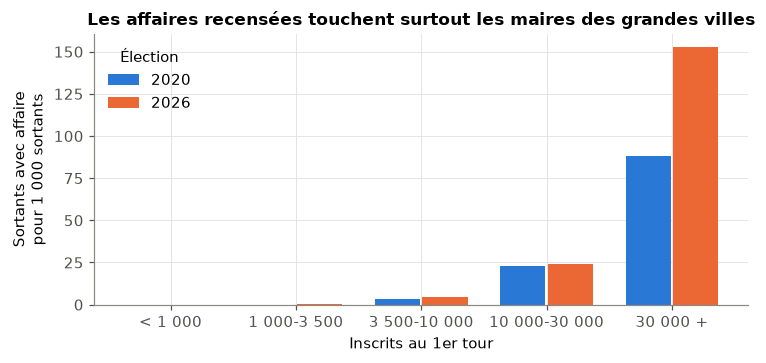

sortants        avec_affaire     
annee             2020   2026         2020 2026
taille                                         
< 1 000           1739  26652            0    2
1 000-3 500       5102   5538            0    2
3 500-10 000      1577   1792            5    8
10 000-30 000      522    538           12   13
30 000 +           125    144           11   22

In [6]:
part = (panel.groupby(["annee", "taille"], observed=True)
        .agg(sortants=("code_insee", "size"), avec_affaire=("affaire_connue", "sum")))
part["pour_1000"] = 1000 * part.avec_affaire / part.sortants

fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(len(An.LIBELLES_TAILLE))
for i, annee in enumerate((2020, 2026)):
    v = part.loc[annee, "pour_1000"].reindex(An.LIBELLES_TAILLE)
    ax.bar(x + (i - 0.5) * 0.38, v, width=0.36, color=COULEURS[annee], label=str(annee))
ax.set_xticks(x, An.LIBELLES_TAILLE)
ax.set_xlabel("Inscrits au 1er tour")
ax.set_ylabel("Sortants avec affaire\npour 1 000 sortants")
ax.set_title("Les affaires recensées touchent surtout les maires des grandes villes")
ax.legend(title="Élection")
plt.tight_layout()
plt.show()
part.unstack("annee")[["sortants", "avec_affaire"]]

## 4. Le sortant visé par une affaire se représente-t-il ?

In [7]:
temoin_tous = ~(panel.affaire_connue | panel.affaire_apres | panel.affaire_ambigue)
panel["candidat"] = panel.sortant_candidat.astype(float)
pd.DataFrame({
    t: An.ecart_stratifie(panel[panel[t] | temoin_tous], "candidat", t, ["annee", "taille"])
    for t in ["affaire_connue", "affaire_mandat", "affaire_apres"]
}).T.round(3)

,n_traites,n_temoins,ecart,ic_bas,ic_haut
affaire_connue,75.0,43584.0,0.070,0.009,0.123
affaire_mandat,40.0,43584.0,0.046,-0.046,0.118
affaire_apres,68.0,43584.0,0.132,0.069,0.191


**Lecture.** L'écart est la différence de taux de candidature entre les sortants
visés par une affaire et les autres sortants des communes de même taille, à la même
élection (en proportion : 0,07 = 7 points). Les sortants visés par une affaire **se
représentent plutôt plus souvent** que les autres. Mais c'est aussi le cas de ceux
dont l'affaire n'éclatera qu'après le scrutin (`affaire_apres`) : il s'agit d'élus de
carrière, qui se représentent davantage. Rien n'indique qu'une affaire pousse au retrait.

## 5. Leur score et leur victoire

On reprend le champ du notebook 02 : sortants têtes de liste aux deux élections, dans
des communes disputées les deux fois. Le résultat est l'**évolution du score** au 1er
tour (en points de % des exprimés) et la **victoire** de la liste du sortant.

Le groupe témoin rassemble les sortants sans affaire recensée. Les intervalles sont à
95 % (bootstrap) : avec quelques dizaines de traités, ils sont larges.

In [8]:
champ = panel[(panel.n_listes > 1) & panel.sortant_tete_liste.fillna(False) & panel.tete_liste_prec].copy()
champ["gagne"] = champ.liste_sortant_gagnante.astype(float)
temoin = ~(champ.affaire_connue | champ.affaire_apres | champ.affaire_ambigue)

TRAITEMENTS = {
    "affaire_connue": "Affaire connue avant le vote",
    "affaire_mandat": "Révélée pendant le mandat",
    "affaire_probite_mandat": "dont atteinte à la probité",
    "affaire_apres": "Révélée après le vote (placebo)",
}
lignes = []
for t in TRAITEMENTS:
    d = champ[champ[t] | temoin]
    for y in ("delta_pct_voix_exp", "gagne"):
        lignes.append(An.ecart_stratifie(d, y, t, ["annee", "taille"]).rename((t, y, "ensemble")))
        for annee in (2020, 2026):
            lignes.append(An.ecart_stratifie(d[d.annee == annee], y, t, ["taille"]).rename((t, y, annee)))
res = pd.DataFrame(lignes)
res.index.names = ["traitement", "resultat", "election"]
res.round(2)

n_traites  n_temoins  ecart  ic_bas  ic_haut
traitement             resultat           election                                              
affaire_connue         delta_pct_voix_exp ensemble       61.0     6745.0  -2.45   -5.90     1.20
                                          2020           22.0     3251.0  -0.08   -7.47     7.53
                                          2026           39.0     3494.0  -3.78   -7.72     0.29
                       gagne              ensemble       61.0     6745.0   0.01   -0.09     0.11
                                          2020           22.0     3251.0   0.07   -0.08     0.20
                                          2026           39.0     3494.0  -0.02   -0.15     0.11
affaire_mandat         delta_pct_voix_exp ensemble       32.0     6745.0  -2.62   -7.07     2.18
                                          2020            8.0     3251.0   5.43   -3.73    14.94
                                          2026           24.0     3494.0  -5.30  -10.53    -0.05
                       gagne              ensemble       32.0     6745.0  -0.04   -0.19     0.10
                                          2020            8.0     3251.0   0.07   -0.19     0.23
                                          2026           24.0     3494.0  -0.08   -0.28     0.10
affaire_probite_mandat delta_pct_voix_exp ensemble       15.0     6745.0  -1.24   -7.24     4.69
                                          2020            3.0     3251.0   7.38   -7.69    29.49
                                          2026           12.0     3494.0  -3.39   -9.15     2.44
                       gagne              ensemble       15.0     6745.0   0.15    0.01     0.24
                                          2020            3.0     3251.0   0.20    0.16     0.25
                                          2026           12.0     3494.0   0.13   -0.05     0.25
affaire_apres          delta_pct_voix_exp ensemble       54.0     6745.0  -1.81   -5.66     2.01
                                          2020           47.0     3251.0  -0.19   -4.33     4.33
                                          2026            7.0     3494.0 -12.67  -21.23    -2.98
                       gagne              ensemble       54.0     6745.0   0.11    0.03     0.19
                                          2020           47.0     3251.0   0.14    0.04     0.22
                                          2026            7.0     3494.0  -0.06   -0.23     0.21

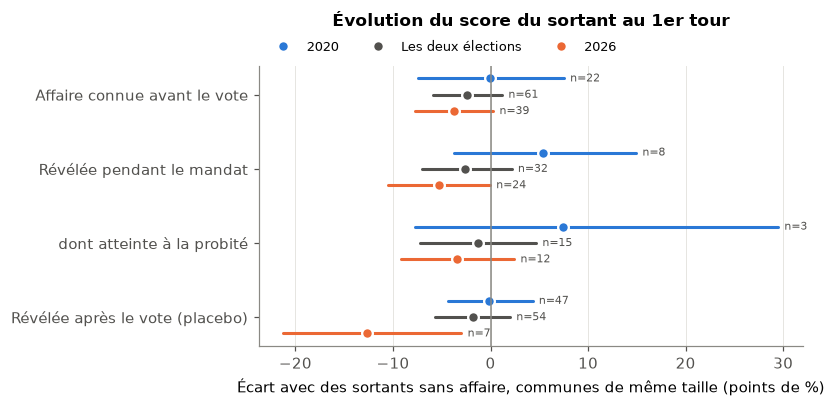

In [9]:
def graphique(resultat: str, titre: str, unite: str, echelle: float = 1):
    r = res.xs(resultat, level="resultat")
    fig, ax = plt.subplots(figsize=(7.5, 3.8))
    positions = {2020: -0.22, "ensemble": 0, 2026: 0.22}
    couleurs = {2020: COULEURS[2020], "ensemble": ENCRE, 2026: COULEURS[2026]}
    noms = {2020: "2020", "ensemble": "Les deux élections", 2026: "2026"}
    for i, t in enumerate(TRAITEMENTS):
        for e, dy in positions.items():
            v = r.loc[(t, e)].copy()
            v[["ecart", "ic_bas", "ic_haut"]] *= echelle
            ax.plot([v.ic_bas, v.ic_haut], [i + dy] * 2, color=couleurs[e], lw=2, solid_capstyle="round")
            ax.plot(v.ecart, i + dy, "o", ms=7, color=couleurs[e], mec="white", mew=1.5,
                    label=noms[e] if i == 0 else None)
            ax.annotate(f"n={int(v.n_traites)}", (max(v.ic_haut, v.ecart), i + dy), xytext=(4, 0),
                        textcoords="offset points", va="center", fontsize=7.5, color=ENCRE)
    ax.axvline(0, color="#8a8984", lw=1)
    ax.set_yticks(range(len(TRAITEMENTS)), TRAITEMENTS.values())
    ax.invert_yaxis()
    ax.grid(axis="y", visible=False)
    ax.set_xlabel(f"Écart avec des sortants sans affaire, communes de même taille ({unite})")
    ax.set_title(titre, pad=26)
    ax.legend(loc="lower left", bbox_to_anchor=(0, 1.0), ncol=3, fontsize=8.5)
    plt.tight_layout()
    plt.show()

graphique("delta_pct_voix_exp", "Évolution du score du sortant au 1er tour", "points de %")

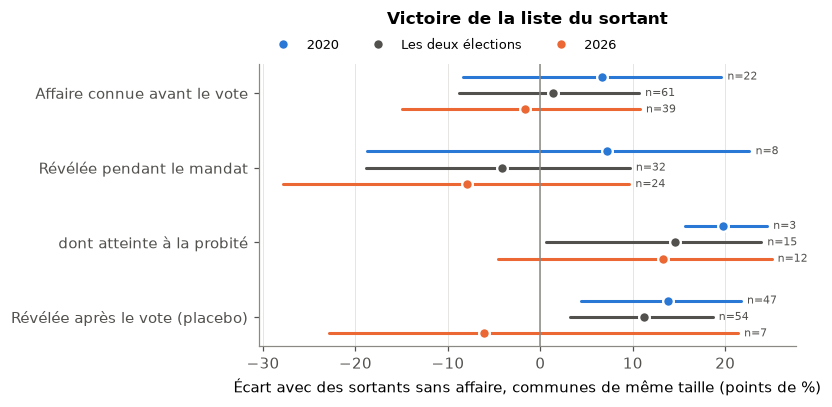

In [10]:
graphique("gagne", "Victoire de la liste du sortant", "points de %", echelle=100)

**Lecture.**

- **Score.** En 2026, un sortant dont l'affaire a éclaté pendant le mandat perd
  environ 5 points de plus que des sortants comparables. L'intervalle exclut zéro,
  mais de justesse (de -10,5 à -0,1) : c'est un indice, pas une preuve. En 2020, il n'y a que 8 cas et
  rien de visible. Sur les deux élections réunies, la perte estimée est de 2 à
  3 points, avec un intervalle qui contient zéro.
- **Victoire.** La perte de voix ne se traduit pas en défaites : la liste du sortant
  gagne à peu près aussi souvent que celle de ses pairs. Le notebook 02 a montré
  qu'une victoire ne bascule qu'au-delà de pertes bien plus fortes (10 à 20 points).
- **Probité.** Les atteintes à la probité ne sont pas plus sanctionnées que les
  autres affaires. Ces sortants gagnent même plus souvent que leurs pairs, mais ils
  ne sont qu'une quinzaine.
- **Placebo.** Les sortants dont l'affaire n'éclatera qu'**après** le scrutin gagnent
  *plus souvent* que leurs pairs (environ +11 points sur les deux élections). Les
  électeurs ne pouvaient pas réagir à une affaire inconnue : cet écart mesure la
  prime des élus notoires, pas l'effet d'une affaire. Comparer les sortants « avec
  affaire » à des sortants ordinaires sous-estime donc la sanction. Le bon point de
  comparaison est ce groupe d'élus du même profil.

## 6. À notoriété égale : affaire connue contre affaire future

On compare directement les sortants dont l'affaire était connue au vote à ceux dont
l'affaire éclatera plus tard. Les deux groupes sont des élus du même type, présents
dans les mêmes sources. Seule l'élection de 2020 offre assez d'affaires « futures »
pour cette comparaison (en 2026, elles n'ont pas encore eu le temps d'éclater).

In [11]:
notoires = champ[(champ.annee == 2020) & (champ.affaire_connue | champ.affaire_apres)]
display(pd.crosstab(notoires.taille, notoires.affaire_connue.map({True: "connue", False: "future"})))
pd.DataFrame({
    y: An.ecart_stratifie(notoires, y, "affaire_connue", ["taille"])
    for y in ("delta_pct_voix_exp", "gagne")
}).T.round(2)

affaire_connue,connue,future
taille,,
1 000-3 500,0,1
3 500-10 000,5,5
10 000-30 000,8,18
30 000 +,9,17


,n_traites,n_temoins,ecart,ic_bas,ic_haut
delta_pct_voix_exp,22.0,41.0,-0.70,-9.10,7.95
gagne,22.0,41.0,-0.07,-0.23,0.09


**Lecture.** À taille égale, un sortant dont l'affaire était connue gagne environ
7 points de moins qu'un élu comparable dont l'affaire n'était pas encore sortie, et
son score évolue à peu près de la même façon. Avec 22 et 41 sortants, l'intervalle
reste très large : on ne peut pas exclure l'absence d'effet.

## Ce qu'il faut retenir

- 181 rapprochements (personnalité, sortant) confirmés : 75 sortants avaient une
  affaire connue au moment du vote, dont 40 révélée pendant le mandat sortant.
- Ces sortants sont des maires de grandes villes, souvent des figures nationales :
  ils se représentent et gagnent au moins autant que leurs pairs.
- L'indice le plus net est une **perte de score de l'ordre de 5 points en 2026**
  quand l'affaire a éclaté pendant le mandat. Elle reste à la limite de la
  significativité et ne coûte pas la mairie.
- Les élus notoires bénéficient d'une prime électorale. Mesurée par le groupe
  placebo, elle est du même ordre que la sanction éventuelle : les deux se compensent.

**Limites.**

1. *Couverture* : seuls les élus ayant une page Wikipédia ou une fiche Poligraph sont
   recensés. Les affaires visant des maires de petites communes, de loin les plus
   nombreuses, échappent à l'étude.
2. *Datation* : la date de procédure ou de verdict est postérieure à la révélation
   médiatique. Certaines affaires classées « après le vote » étaient peut-être déjà
   connues.
3. *Sortants 2020* : il s'agit de la tête de la liste gagnante de 2014. Les départs en
   cours de mandat ne sont corrigés que pour les personnalités recensées.
4. *Effectifs* : quelques dizaines de traités. Les conclusions sont des ordres de
   grandeur, pas des effets précisément estimés.